In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("construction_cost_analysis_150_projects.csv")

df.head()

,Project_ID,Project_Size,Location,Duration,Planned_Labour_Cost,Actual_Labour_Cost,Planned_Material_Cost,Actual_Material_Cost,Equipment_Cost,Subcontracting_Cost
0,P044,Large,Pune,368,2215000.0,2317000.0,1877000.0,2127000.0,256000.0,540000.0
1,P038,Small,Bangalore,107,279000.0,277000.0,818000.0,945000.0,170000.0,184000.0
2,P144,Medium,Bangalore,234,975000.0,1048000.0,1350000.0,1377000.0,268000.0,347000.0
3,P146,Medium,Hyderabad,159,476000.0,478000.0,1150000.0,1174000.0,207000.0,300000.0
4,P108,Small,Pune,130,298000.0,292000.0,697000.0,725000.0,139000.0,181000.0


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 150
Number of columns: 10


In [4]:
print(df.columns.tolist())


['Project_ID', 'Project_Size', 'Location', 'Duration', 'Planned_Labour_Cost', 'Actual_Labour_Cost', 'Planned_Material_Cost', 'Actual_Material_Cost', 'Equipment_Cost', 'Subcontracting_Cost']


In [5]:
df.isnull().sum()

Project_ID               0
Project_Size             0
Location                 0
Duration                 0
Planned_Labour_Cost      0
Actual_Labour_Cost       0
Planned_Material_Cost    0
Actual_Material_Cost     0
Equipment_Cost           0
Subcontracting_Cost      0
dtype: int64

In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Project IDs:", df["Project_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Project IDs: 0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Project_ID             150 non-null    object 
 1   Project_Size           150 non-null    object 
 2   Location               150 non-null    object 
 3   Duration               150 non-null    int64  
 4   Planned_Labour_Cost    150 non-null    float64
 5   Actual_Labour_Cost     150 non-null    float64
 6   Planned_Material_Cost  150 non-null    float64
 7   Actual_Material_Cost   150 non-null    float64
 8   Equipment_Cost         150 non-null    float64
 9   Subcontracting_Cost    150 non-null    float64
dtypes: float64(6), int64(1), object(3)
memory usage: 11.8+ KB


In [8]:
df.describe()

,Duration,Planned_Labour_Cost,Actual_Labour_Cost,Planned_Material_Cost,Actual_Material_Cost,Equipment_Cost,Subcontracting_Cost
count,150.000000,1.500000e+02,1.500000e+02,1.500000e+02,1.500000e+02,150.000000,150.000000
mean,220.766667,9.326333e+05,9.548467e+05,1.189407e+06,1.240480e+06,238666.666667,339153.333333
std,91.682368,7.072787e+05,7.364223e+05,4.830585e+05,5.114791e+05,99315.487189,149019.918342
min,60.000000,1.500000e+05,1.240000e+05,4.510000e+05,4.840000e+05,75000.000000,99000.000000
25%,151.000000,3.487500e+05,3.505000e+05,7.660000e+05,8.110000e+05,148000.000000,216000.000000
50%,217.000000,7.305000e+05,7.630000e+05,1.099000e+06,1.131500e+06,226500.000000,307500.000000
75%,289.750000,1.647500e+06,1.645750e+06,1.513250e+06,1.595750e+06,296750.000000,419250.000000
max,411.000000,2.628000e+06,2.792000e+06,2.393000e+06,2.483000e+06,497000.000000,763000.000000


In [9]:
df["Labour_Variance"] = (
    df["Actual_Labour_Cost"] - df["Planned_Labour_Cost"]
)

df["Material_Variance"] = (
    df["Actual_Material_Cost"] - df["Planned_Material_Cost"]
)

df["Total_Variance"] = (
    df["Labour_Variance"] + df["Material_Variance"]
)

df[[
    "Project_ID",
    "Labour_Variance",
    "Material_Variance",
    "Total_Variance"
]].head()

,Project_ID,Labour_Variance,Material_Variance,Total_Variance
0,P044,102000.0,250000.0,352000.0
1,P038,-2000.0,127000.0,125000.0
2,P144,73000.0,27000.0,100000.0
3,P146,2000.0,24000.0,26000.0
4,P108,-6000.0,28000.0,22000.0


In [10]:
df["Planned_Total_Cost"] = (
    df["Planned_Labour_Cost"] +
    df["Planned_Material_Cost"]
)

df["Actual_Total_Cost"] = (
    df["Actual_Labour_Cost"] +
    df["Actual_Material_Cost"]
)

df["Variance_Percentage"] = (
    df["Total_Variance"] /
    df["Planned_Total_Cost"]
) * 100

In [11]:
df[[
    "Project_ID",
    "Planned_Total_Cost",
    "Actual_Total_Cost",
    "Total_Variance",
    "Variance_Percentage"
]].head(10)

,Project_ID,Planned_Total_Cost,Actual_Total_Cost,Total_Variance,Variance_Percentage
0,P044,4092000.0,4444000.0,352000.0,8.602151
1,P038,1097000.0,1222000.0,125000.0,11.394713
2,P144,2325000.0,2425000.0,100000.0,4.301075
3,P146,1626000.0,1652000.0,26000.0,1.599016
4,P108,995000.0,1017000.0,22000.0,2.211055
5,P053,1880000.0,1988000.0,108000.0,5.744681
6,P061,1942000.0,1932000.0,-10000.0,-0.514933
7,P042,881000.0,838000.0,-43000.0,-4.880817
8,P123,1001000.0,1042000.0,41000.0,4.095904
9,P132,1124000.0,1204000.0,80000.0,7.117438


In [12]:
total_labour_variance = df["Labour_Variance"].sum()
total_material_variance = df["Material_Variance"].sum()

print("Total Labour Variance: ₹", total_labour_variance)
print("Total Material Variance: ₹", total_material_variance)

if total_labour_variance > total_material_variance:
    print("\nLabour is the larger source of cost overruns.")
else:
    print("\nMaterial is the larger source of cost overruns.")

Total Labour Variance: ₹ 3332000.0
Total Material Variance: ₹ 7661000.0

Material is the larger source of cost overruns.


In [13]:
top_overruns = df.sort_values(
    by="Total_Variance",
    ascending=False
)

top_overruns[[
    "Project_ID",
    "Project_Size",
    "Location",
    "Duration",
    "Total_Variance",
    "Variance_Percentage"
]].head(10)

,Project_ID,Project_Size,Location,Duration,Total_Variance,Variance_Percentage
44,P071,Large,Pune,289,421000.0,11.543735
26,P054,Large,Bangalore,329,396000.0,9.799555
81,P101,Large,Hyderabad,411,378000.0,8.488659
72,P120,Large,Bangalore,386,377000.0,8.670653
0,P044,Large,Pune,368,352000.0,8.602151
88,P049,Large,Chennai,399,336000.0,7.790401
115,P039,Large,Chennai,318,327000.0,7.948469
48,P095,Large,Madurai,383,326000.0,8.988144
92,P100,Large,Pune,334,307000.0,8.169239
78,P082,Large,Bangalore,404,248000.0,5.356371


In [14]:
df["Project_Size"].value_counts()

Project_Size
Medium    63
Small     46
Large     41
Name: count, dtype: int64

In [15]:
size_analysis = df.groupby("Project_Size").agg(
    Average_Variance=("Total_Variance", "mean"),
    Average_Variance_Percentage=("Variance_Percentage", "mean"),
    Average_Duration=("Duration", "mean"),
    Number_of_Projects=("Project_ID", "count")
).round(2)

size_analysis

,Average_Variance,Average_Variance_Percentage,Average_Duration,Number_of_Projects
Project_Size,,,,
Large,153121.95,3.96,343.59,41
Medium,50984.13,2.77,214.24,63
Small,32673.91,3.45,120.24,46


In [16]:
location_analysis = df.groupby("Location").agg(
    Average_Variance=("Total_Variance", "mean"),
    Average_Variance_Percentage=("Variance_Percentage", "mean"),
    Average_Duration=("Duration", "mean"),
    Number_of_Projects=("Project_ID", "count")
).sort_values(
    by="Average_Variance",
    ascending=False
).round(2)

location_analysis

,Average_Variance,Average_Variance_Percentage,Average_Duration,Number_of_Projects
Location,,,,
Bangalore,110034.48,4.45,242.17,29
Madurai,86750.00,3.94,259.17,12
Pune,80857.14,3.39,211.90,21
Hyderabad,77370.37,3.97,206.96,27
Chennai,60410.26,2.55,223.74,39
Coimbatore,28090.91,1.90,191.73,22


In [17]:
duration_correlation = df["Duration"].corr(
    df["Total_Variance"]
)

print(
    "Correlation between Duration and Cost Variance:",
    round(duration_correlation, 3)
)

Correlation between Duration and Cost Variance: 0.433


In [18]:
df["Duration_Group"] = pd.cut(
    df["Duration"],
    bins=[0, 150, 250, 350, 500],
    labels=[
        "Short",
        "Medium",
        "Long",
        "Very Long"
    ]
)

duration_analysis = df.groupby(
    "Duration_Group",
    observed=True
).agg(
    Average_Variance=("Total_Variance", "mean"),
    Average_Variance_Percentage=("Variance_Percentage", "mean"),
    Number_of_Projects=("Project_ID", "count")
).round(2)

duration_analysis

,Average_Variance,Average_Variance_Percentage,Number_of_Projects
Duration_Group,,,
Short,37972.97,3.92,37
Medium,42206.35,2.46,63
Long,137406.25,4.22,32
Very Long,140666.67,3.39,18


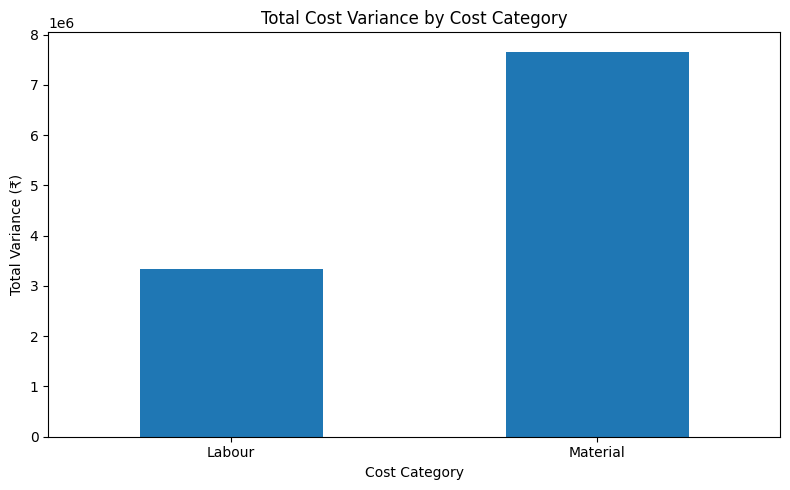

In [19]:
variance_totals = pd.Series({
    "Labour": df["Labour_Variance"].sum(),
    "Material": df["Material_Variance"].sum()
})

plt.figure(figsize=(8, 5))

variance_totals.plot(
    kind="bar"
)

plt.title("Total Cost Variance by Cost Category")
plt.xlabel("Cost Category")
plt.ylabel("Total Variance (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

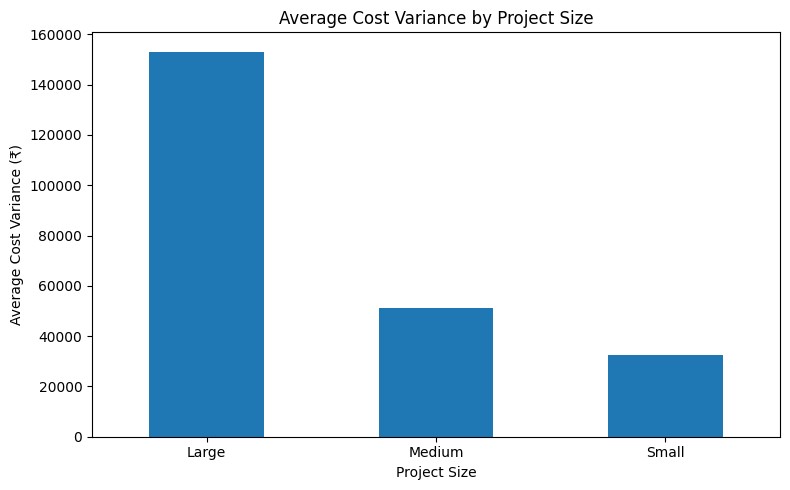

In [20]:
size_analysis["Average_Variance"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Cost Variance by Project Size")
plt.xlabel("Project Size")
plt.ylabel("Average Cost Variance (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

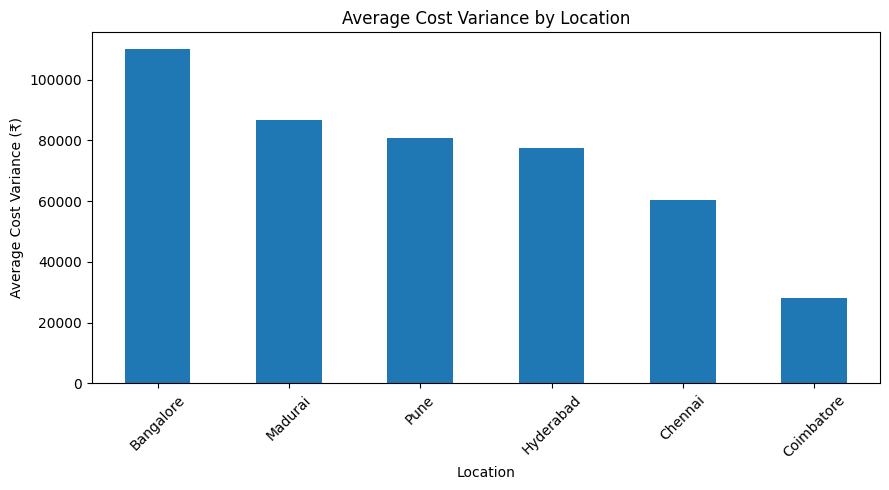

In [21]:
location_analysis["Average_Variance"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Cost Variance by Location")
plt.xlabel("Location")
plt.ylabel("Average Cost Variance (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

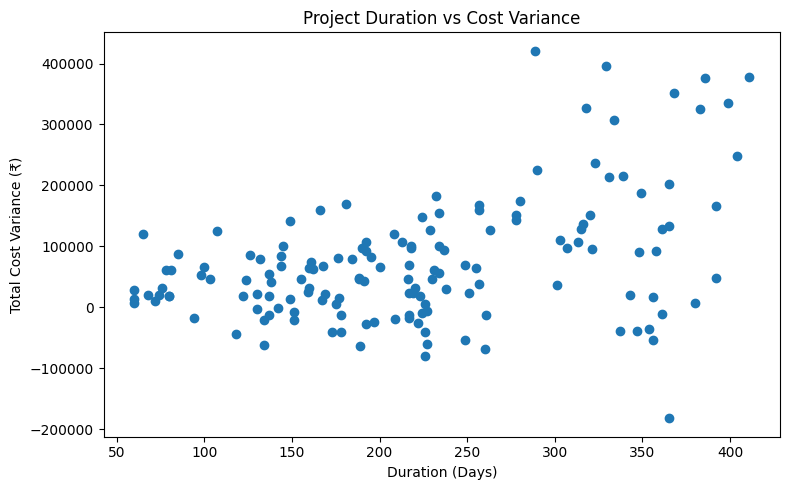

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Duration"],
    df["Total_Variance"]
)

plt.title("Project Duration vs Cost Variance")
plt.xlabel("Duration (Days)")
plt.ylabel("Total Cost Variance (₹)")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [24]:
X = df[
    [
        "Duration",
        "Planned_Labour_Cost",
        "Planned_Material_Cost",
        "Equipment_Cost",
        "Subcontracting_Cost"
    ]
]

y = df["Total_Variance"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Total_Variance")

Features:
['Duration', 'Planned_Labour_Cost', 'Planned_Material_Cost', 'Equipment_Cost', 'Subcontracting_Cost']

Target:
Total_Variance


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [26]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [27]:
y_pred = model.predict(X_test)

print("Predicted Cost Variances:")
print(y_pred[:10])

Predicted Cost Variances:
[ 24151.53805139  52222.839464    45923.52272111 221904.65836393
 140914.46460975  38219.86533118  27193.85355039  41849.49384647
  48957.08690558 186697.58078485]


In [28]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE  :", round(mae, 2))
print("MSE  :", round(mse, 2))
print("RMSE :", round(rmse, 2))
print("R²   :", round(r2, 4))

Model Evaluation Results
------------------------
MAE  : 54701.06
MSE  : 6305373802.34
RMSE : 79406.38
R²   : 0.3227


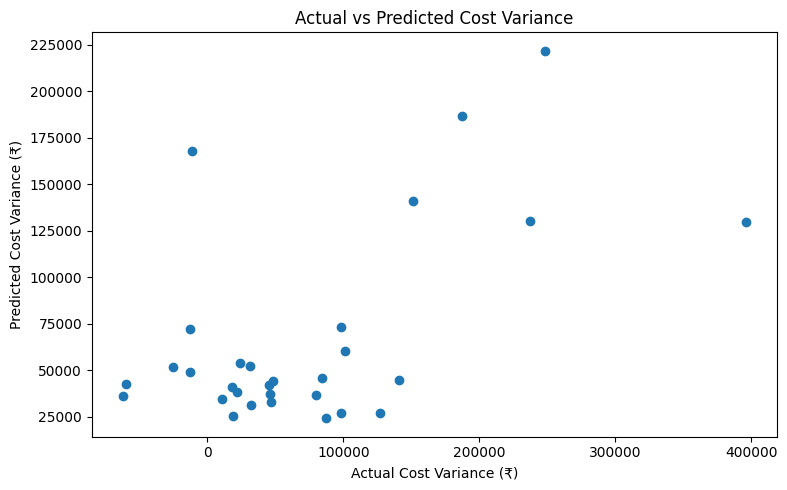

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Cost Variance (₹)")
plt.ylabel("Predicted Cost Variance (₹)")
plt.title("Actual vs Predicted Cost Variance")

plt.tight_layout()
plt.show()

In [30]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients

,Feature,Coefficient
0,Duration,-220.849618
1,Planned_Labour_Cost,0.146858
2,Planned_Material_Cost,0.027133
3,Equipment_Cost,-0.189134
4,Subcontracting_Cost,-0.233277


In [31]:
print("Intercept:", model.intercept_)

Intercept: 75782.6560052609


In [32]:
df.to_csv(
    "construction_cost_analysis_final.csv",
    index=False
)

print("Final analyzed dataset saved successfully!")

Final analyzed dataset saved successfully!


In [33]:
print("=" * 60)
print("CONSTRUCTION COST VARIANCE - FINAL SUMMARY")
print("=" * 60)

print("\n1. Total Labour Variance:")
print(f"₹{df['Labour_Variance'].sum():,.0f}")

print("\n2. Total Material Variance:")
print(f"₹{df['Material_Variance'].sum():,.0f}")

print("\n3. Average Cost Variance:")
print(f"₹{df['Total_Variance'].mean():,.0f}")

print("\n4. Average Variance Percentage:")
print(f"{df['Variance_Percentage'].mean():.2f}%")

print("\n5. Highest Cost Overrun Project:")
highest = df.loc[df['Total_Variance'].idxmax()]
print(highest['Project_ID'])
print(f"Variance: ₹{highest['Total_Variance']:,.0f}")

print("\n6. Highest Average Variance by Location:")
print(location_analysis['Average_Variance'].idxmax())

print("\n7. Highest Average Variance by Project Size:")
print(size_analysis['Average_Variance'].idxmax())

print("\n8. Duration vs Variance Correlation:")
print(round(duration_correlation, 3))

print("\n9. Linear Regression R²:")
print(round(r2, 4))

CONSTRUCTION COST VARIANCE - FINAL SUMMARY

1. Total Labour Variance:
₹3,332,000

2. Total Material Variance:
₹7,661,000

3. Average Cost Variance:
₹73,287

4. Average Variance Percentage:
3.31%

5. Highest Cost Overrun Project:
P071
Variance: ₹421,000

6. Highest Average Variance by Location:
Bangalore

7. Highest Average Variance by Project Size:
Large

8. Duration vs Variance Correlation:
0.433

9. Linear Regression R²:
0.3227


In [34]:
labour_overrun_projects = (df["Labour_Variance"] > 0).sum()
material_overrun_projects = (df["Material_Variance"] > 0).sum()

print(
    "Projects with Labour Overrun:",
    labour_overrun_projects,
    "out of",
    len(df)
)

print(
    "Projects with Material Overrun:",
    material_overrun_projects,
    "out of",
    len(df)
)

Projects with Labour Overrun: 90 out of 150
Projects with Material Overrun: 112 out of 150


In [35]:
print(
    "Labour Overrun Rate:",
    round(labour_overrun_projects / len(df) * 100, 2),
    "%"
)

print(
    "Material Overrun Rate:",
    round(material_overrun_projects / len(df) * 100, 2),
    "%"
)

Labour Overrun Rate: 60.0 %
Material Overrun Rate: 74.67 %
